# Option 2: Logistic Regression
## Step 0: Import Libraries & Load Data

In [110]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_STATE = 27

In [111]:
data_path = "./data"
train_df = pd.read_csv(f"{data_path}/train.csv")
test_df = pd.read_csv(f"{data_path}/test.csv")

## Step 1: Split the Training Data

In [112]:
from sklearn.model_selection import train_test_split

X = train_df.drop(columns=["label"])
y = train_df["label"]
X_train, X_dev, y_train, y_dev = train_test_split(X, y, test_size=2000, random_state=RANDOM_STATE, stratify=y)
X_dev[["id"]].to_csv("val_ids.csv", index=False)
print(len(X_train), len(X_dev))

8000 2000


In [113]:
# Sample a few examples of each class to see what the data looks like
for label in [0, 1]:
    print(f"===== label {label} ({'AI' if label else 'human'}) =====")
    for t in X_train[y_train == label]["text"].sample(3, random_state=RANDOM_STATE):
        print(t[:400], "\n")

===== label 0 (human) =====
Crystalline Fe3O4/NiO bilayers were grown on MgO(001) substrates using
reactive molecular beam epitaxy to investigate their structural properties and
their morphology. The film thickness either of the Fe3O4 film or of the NiO
film has been varied to shed light on the relaxation of the bilayer system. The
surface properties as studied by x-ray photo electron spectroscopy and low
energy electron dif 

8 ounces whole-grain medium shell pasta
4 plum tomatoes, halved lengthwise
2 tablespoons whole wheat breadcrumbs
1 teaspoon plus 1 tablespoon olive oil
1/2 teaspoon Italian seasoning
1 tablespoon all-purpose flour
1 clove garlic, minced
1/2 cup canned pumpkin puree
One 12-ounce can nonfat evaporated milk
1/2 cup reduced-fat shredded Cheddar
1/2 cup part-skim mozzarella
1/4 cup grated Parmesan
Kosh 

Upgraded electronics, improved water system dynamics, better calibration and
analysis techniques allowed Super-Kamiokande-IV to clearly observe very
low-energy 8B sol

## Step 2: Vectorize Data

In [114]:
from sklearn.feature_extraction.text import TfidfVectorizer

train_text = X_train["text"]  # TfidfVectorizer still lowercases and drops punctuation by default
dev_text = X_dev["text"]

M = 2
vectorizer = TfidfVectorizer(min_df=M, ngram_range=(1, 2), sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(train_text)  # learn vocabulary + IDF from training text only
X_dev_tfidf = vectorizer.transform(dev_text)          # reuse them on validation
print(X_train_tfidf.shape, X_dev_tfidf.shape)

(8000, 167660) (2000, 167660)


## Step 3: Logistic Regression

### Evaluate Functions

In [ ]:
# Import logistic regression model from sklearn
import time

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


def evaluate(model, X_tra, y_tra, X_va, y_va):
    """
    Fit a classifier and evaluate it on the training and validation sets.

    Parameters:
    - model: sklearn classifier with a predict_proba method.
    - X_tra, y_tra: training features and labels.
    - X_va, y_va: validation features and labels.
    ...

    Returns:
    - res: dictionary, containing training AUROC, validation AUROC, and training time.
    """
    start = time.perf_counter()
    model.fit(X_tra, y_tra)
    train_time = time.perf_counter() - start

    train_auroc = roc_auc_score(y_tra, model.predict_proba(X_tra)[:, 1])
    val_auroc = roc_auc_score(y_va, model.predict_proba(X_va)[:, 1])
    print(f"Train AUROC: {train_auroc:.4f} | Val AUROC: {val_auroc:.4f} | Time: {train_time:.1f}s")
    res = {"train_auroc": train_auroc, "val_auroc": val_auroc, "train_time": train_time}
    return res

def run_c_grid(penalty, X_tr, y_tr, X_va, y_va, C_values):
    """
    Train logistic regression at each C value and collect the results.

    Parameters:
    - penalty: str, either "L1" or "L2" to specify the regularization type.
    - X_tr, y_tr: training features and labels.
    - X_va, y_va: validation features and labels.
    - C_values: iterable of floats, C values to try (inverse regularization strength).

    Returns:
    - results_df: pd.DataFrame, one row per (penalty, C) with train/validation
      AUROC, train time, and the number of nonzero weights.
    """
    results = []
    for C in C_values:
        if penalty == "L1":
            model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                        l1_ratio=1.0, solver="liblinear", C=C)
        else:
            model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                        l1_ratio=0, C=C)

        print(f"{penalty}, C={C:g}: ", end="")
        res = evaluate(model, X_tr, y_tr, X_va, y_va)
        res.update({"penalty": penalty, "C": C,
                    "nonzero_weights": int((model.coef_ != 0).sum())})
        results.append(res)

    return pd.DataFrame(results)


C_values = np.logspace(-2, 5, 8)  # 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000


### No Regularization Model

In [116]:
model_noreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, C=np.inf)
noreg_res = evaluate(model_noreg, X_train_tfidf, y_train, X_dev_tfidf, y_dev)


Train AUROC: 1.0000 | Val AUROC: 0.9402 | Time: 0.3s


### L1 Regularization Model

In [117]:
l1_grid = run_c_grid("L1", X_train_tfidf, y_train, X_dev_tfidf, y_dev, C_values)
l1_grid

L1, C=0.01: Train AUROC: 0.5000 | Val AUROC: 0.5000 | Time: 0.1s
L1, C=0.1: Train AUROC: 0.6734 | Val AUROC: 0.6674 | Time: 0.9s
L1, C=1: Train AUROC: 0.9172 | Val AUROC: 0.9011 | Time: 0.6s
L1, C=10: Train AUROC: 0.9999 | Val AUROC: 0.9323 | Time: 1.4s
L1, C=100: Train AUROC: 1.0000 | Val AUROC: 0.9273 | Time: 1.2s
L1, C=1000: Train AUROC: 1.0000 | Val AUROC: 0.9256 | Time: 0.4s
L1, C=10000: Train AUROC: 1.0000 | Val AUROC: 0.9256 | Time: 0.4s
L1, C=100000: Train AUROC: 1.0000 | Val AUROC: 0.9237 | Time: 0.5s


,train_auroc,val_auroc,train_time,penalty,C,nonzero_weights
0,0.500000,0.500000,0.105021,L1,0.01,0
1,0.673364,0.667446,0.880712,L1,0.10,2
2,0.917195,0.901085,0.584232,L1,1.00,189
3,0.999944,0.932325,1.371531,L1,10.00,2075
4,1.000000,0.927340,1.185015,L1,100.00,2838
5,1.000000,0.925641,0.377328,L1,1000.00,5296
6,1.000000,0.925650,0.374666,L1,10000.00,12704
7,1.000000,0.923699,0.495373,L1,100000.00,29725


### L2 Regularization Model

In [118]:
l2_grid = run_c_grid("L2", X_train_tfidf, y_train, X_dev_tfidf, y_dev, C_values)
l2_grid

L2, C=0.01: Train AUROC: 0.9441 | Val AUROC: 0.8804 | Time: 0.1s
L2, C=0.1: Train AUROC: 0.9648 | Val AUROC: 0.9006 | Time: 0.1s
L2, C=1: Train AUROC: 0.9957 | Val AUROC: 0.9306 | Time: 0.1s
L2, C=10: Train AUROC: 1.0000 | Val AUROC: 0.9421 | Time: 0.3s
L2, C=100: Train AUROC: 1.0000 | Val AUROC: 0.9430 | Time: 0.3s
L2, C=1000: Train AUROC: 1.0000 | Val AUROC: 0.9389 | Time: 0.2s
L2, C=10000: Train AUROC: 1.0000 | Val AUROC: 0.9405 | Time: 0.3s
L2, C=100000: Train AUROC: 1.0000 | Val AUROC: 0.9403 | Time: 0.2s


,train_auroc,val_auroc,train_time,penalty,C,nonzero_weights
0,0.944129,0.880379,0.068579,L2,0.01,167660
1,0.964781,0.900648,0.074974,L2,0.10,167660
2,0.995660,0.930601,0.142940,L2,1.00,167660
3,1.000000,0.942142,0.272648,L2,10.00,167660
4,1.000000,0.943037,0.304737,L2,100.00,167660
5,1.000000,0.938888,0.173085,L2,1000.00,167660
6,1.000000,0.940510,0.266179,L2,10000.00,167660
7,1.000000,0.940268,0.247051,L2,100000.00,167660


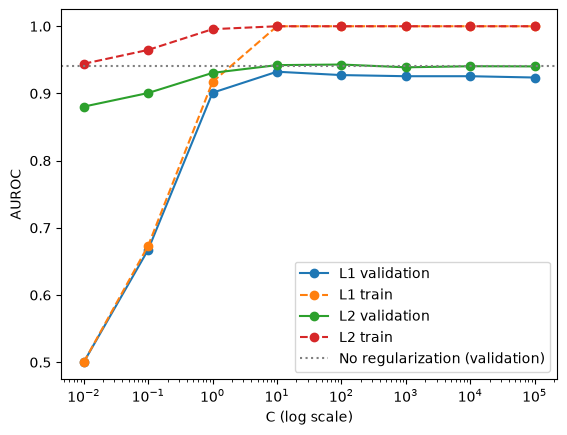

In [119]:
grid_df = {
    "L1": l1_grid,
    "L2": l2_grid
}

for penalty in ["L1", "L2"]:
    sub = grid_df[penalty]
    plt.plot(sub["C"], sub["val_auroc"], marker="o", label=f"{penalty} validation")
    plt.plot(sub["C"], sub["train_auroc"], marker="o", linestyle="--", label=f"{penalty} train")

plt.axhline(noreg_res["val_auroc"], color="gray", linestyle=":", label="No regularization (validation)")
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("AUROC")
plt.legend()
plt.show()

### Naive Bayes

In [120]:
from sklearn.naive_bayes import MultinomialNB


def run_alpha_grid(X_tr, y_tr, X_va, y_va, alpha_values):
    """
    Train Multinomial Naive Bayes at each smoothing value alpha and collect the results.

    Parameters:
    - X_tr, y_tr: training features and labels.
    - X_va, y_va: validation features and labels.
    - alpha_values: iterable of floats, smoothing pseudo-counts to try.

    Returns:
    - results_df: pd.DataFrame, one row per alpha with train/validation AUROC and train time.
    """
    results = []
    for alpha in alpha_values:
        model = MultinomialNB(alpha=alpha)
        print(f"alpha={alpha:g}: ", end="")
        res = evaluate(model, X_tr, y_tr, X_va, y_va)
        res["alpha"] = alpha
        results.append(res)
    return pd.DataFrame(results)


alpha_values = np.logspace(-3, 1, 5)  # 0.001, 0.01, 0.1, 1, 10
nb_df = run_alpha_grid(X_train_tfidf, y_train, X_dev_tfidf, y_dev, alpha_values)
nb_df

alpha=0.001: Train AUROC: 1.0000 | Val AUROC: 0.8792 | Time: 0.0s
alpha=0.01: Train AUROC: 1.0000 | Val AUROC: 0.8869 | Time: 0.0s
alpha=0.1: Train AUROC: 0.9998 | Val AUROC: 0.8934 | Time: 0.0s
alpha=1: Train AUROC: 0.9932 | Val AUROC: 0.8931 | Time: 0.0s
alpha=10: Train AUROC: 0.9672 | Val AUROC: 0.8839 | Time: 0.0s


,train_auroc,val_auroc,train_time,alpha
0,1.000000,0.879156,0.012330,0.001
1,0.999999,0.886872,0.010614,0.010
2,0.999776,0.893431,0.009372,0.100
3,0.993214,0.893120,0.013541,1.000
4,0.967242,0.883932,0.015851,10.000


## Step 4: Run Predictions on Test Data

In [126]:
# 1. Refit vectorizer + model on all 10,000 labeled rows
final_vectorizer = TfidfVectorizer(min_df=M, ngram_range=(1, 2), sublinear_tf=True)
X_full = final_vectorizer.fit_transform(train_df["text"])
X_test = final_vectorizer.transform(test_df["text"])  # transform only, never fit on test

final_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, l1_ratio=0, C=100)
final_model.fit(X_full, train_df["label"])

# 2. Predict P(AI) for each test passage
submission = pd.DataFrame({
    "id": test_df["id"],
    "label": final_model.predict_proba(X_test)[:, 1],
})

# 3. Match the row order of sample_submission.csv
sample_submission = pd.read_csv(f"{data_path}/sample_submission.csv")
submission = submission.set_index("id").loc[sample_submission["id"]].reset_index()

# 4. Sanity checks before uploading
assert list(submission.columns) == ["id", "label"]
assert len(submission) == 3000 and submission["id"].is_unique
assert set(submission["id"]) == set(test_df["id"])
assert submission["label"].between(0, 1).all()

submission.to_csv("submission_lr_word.csv", index=False)
print("Saved 3,000 test predictions to submission_lr_word.csv")

Saved 3,000 test predictions to submission_lr_word.csv


## Step 5: Error Analysis and Feature Exploration

### Most Confident Mistakes of the Best Model (L2, C=100)

In [122]:
# ---------- 5a. Most confident mistakes of the best model (L2, C=100) ----------
# run_c_grid doesn't keep its trained models, so refit the best one here.
best_lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, l1_ratio=0, C=100)
best_lr.fit(X_train_tfidf, y_train)
p_dev = best_lr.predict_proba(X_dev_tfidf)[:, 1]

dev_view = X_dev.assign(label=y_dev.values, p_ai=p_dev)
ai_as_human = dev_view[(dev_view["label"] == 1) & (dev_view["p_ai"] < 0.5)].nsmallest(10, "p_ai")
human_as_ai = dev_view[(dev_view["label"] == 0) & (dev_view["p_ai"] >= 0.5)].nlargest(10, "p_ai")

for name, rows in [("AI scored as human", ai_as_human), ("Human scored as AI", human_as_ai)]:
    print(f"===== {name} =====")
    for _, row in rows.iterrows():
        print(f"id={row['id']}  P(AI)={row['p_ai']:.3f}\n{row['text'][:400]}\n")

===== AI scored as human =====
id=385  P(AI)=0.003
I have a confession to make: I really don't like grey clothing. I know, I know, it's all the rage these days and everyone looks great in it. But for me, it just doesn't work.

First of all, grey clothing stains easily. I'm always getting food or drink on my grey shirts, and it's so hard to get the stains out. And secondly, grey clothing tends to yellow quickly. After a few washes, my grey shirts a

id=4136  P(AI)=0.004
I was a trader at an unnamed bank. We had a position where, if it went sideways in a certain way, there was some risk that the counter part might have to go bankrupt. So we would have to find a new counter party. But we didn't want a new counter party, because getting a new counter party might make that counter party bankrupt so that we would have to get a new new counter party. So instead we just

id=276  P(AI)=0.004
Monday night's marquee match in the SAP Open in San Jose turned out to be anything but as qualifier Jurg

### Candidate Features

In [123]:
import re


# ---------- 5b. Candidate features ----------
def extract_style_features(text):
    """
    Compute lexical, structural, repetition, and punctuation features for one passage.
    Adapted from the team's MLP notebook.

    Parameters:
    - text: str, raw passage text (newlines and punctuation intact).

    Returns:
    - features: dict, feature name -> float.
    """
    text = str(text)
    words = re.findall(r"\b[\w']+\b", text.lower())
    word_count = max(len(words), 1)
    sentences = [s for s in re.split(r"(?<=[.!?])\s+|\n+", text.strip()) if s.strip()]
    paragraphs = [p for p in re.split(r"\n\s*\n", text.strip()) if p.strip()]
    sentence_lengths = [len(re.findall(r"\b[\w']+\b", s)) for s in sentences]
    paragraph_lengths = [len(re.findall(r"\b[\w']+\b", p)) for p in paragraphs]
    word_counts = pd.Series(words).value_counts()
    bigrams = list(zip(words, words[1:]))
    bigram_counts = pd.Series(bigrams).value_counts() if bigrams else pd.Series(dtype=int)
    normalized = text.lower()

    def repeat_fraction(counts, total):
        if total == 0 or len(counts) == 0:
            return 0.0
        return float((counts - 1).clip(lower=0).sum() / total)

    def mean(values):
        return float(np.mean(values)) if values else 0.0

    def std(values):
        return float(np.std(values)) if len(values) > 1 else 0.0

    template_patterns = {
        "not_just_but": r"\bnot just\b.{0,160}\bbut\b",
        "not_only_but_also": r"\bnot only\b.{0,160}\bbut also\b",
        "in_conclusion": r"\bin conclusion\b",
        "it_is_important_to_note": r"\bit is important to note\b",
        "moreover": r"\bmoreover\b",
        "furthermore": r"\bfurthermore\b",
    }
    features = {
        "log_word_count": np.log1p(len(words)),
        "log_character_count": np.log1p(len(text)),
        "mean_word_length": mean([len(w) for w in words]),
        "word_length_std": std([len(w) for w in words]),
        "type_token_ratio": len(set(words)) / word_count,
        "repeated_word_fraction": repeat_fraction(word_counts, len(words)),
        "repeated_bigram_fraction": repeat_fraction(bigram_counts, len(bigrams)),
        "sentence_count": np.log1p(len(sentences)),
        "mean_sentence_length": mean(sentence_lengths),
        "sentence_length_std": std(sentence_lengths),
        "sentence_length_cv": std(sentence_lengths) / max(mean(sentence_lengths), 1.0),
        "paragraph_count": np.log1p(len(paragraphs)),
        "mean_paragraph_length": mean(paragraph_lengths),
        "paragraph_length_std": std(paragraph_lengths),
        "repeated_sentence_fraction": (len(sentences) - len(set(s.strip().lower() for s in sentences))) / max(len(sentences), 1),
        "exclamation_per_100_words": 100 * text.count("!") / word_count,
        "question_per_100_words": 100 * text.count("?") / word_count,
        "comma_per_100_words": 100 * text.count(",") / word_count,
        "semicolon_per_100_words": 100 * text.count(";") / word_count,
        "colon_per_100_words": 100 * text.count(":") / word_count,
        "dash_per_100_words": 100 * (text.count("—") + text.count("–")) / word_count,
        "ellipsis_per_100_words": 100 * (text.count("...") + text.count("…")) / word_count,
        "digit_character_fraction": sum(ch.isdigit() for ch in text) / max(len(text), 1),
        "uppercase_character_fraction": sum(ch.isupper() for ch in text) / max(sum(ch.isalpha() for ch in text), 1),
        "contraction_per_100_words": 100 * len(re.findall(r"\b\w+['’](?:t|re|ve|ll|d|m)\b", normalized)) / word_count,
    }
    for name, pattern in template_patterns.items():
        features[f"template_{name}_per_1000_words"] = 1000 * len(re.findall(pattern, normalized, flags=re.DOTALL)) / word_count
    return features


def extra_features(text):
    """
    Compute candidate features found during error analysis.

    Parameters:
    - text: str, raw passage text (newlines and punctuation intact).

    Returns:
    - features: dict, feature name -> float.
    """
    words = max(len(text.split()), 1)
    lower = text.lower()
    lines = text.split("\n")
    newlines = max(text.count("\n"), 1)
    return {
        "special_symbol_count": sum(text.count(s) for s in "®™©"),
        "first_person_rate": len(re.findall(r"\b(i|me|my|mine)\b", lower)) / words,
        "third_person_rate": len(re.findall(r"\b(he|she|his|her|they|their)\b", lower)) / words,
        "blank_line_fraction": sum(1 for line in lines if not line.strip()) / len(lines),  # recipe spacing
        "starts_with_gt": int(text.lstrip().startswith(">")),                                # ">" prefix
        "mid_sentence_break_rate": len(re.findall(r"[a-z,]\n[a-z]", text)) / newlines,       # hard line wraps
    }

### Test Each Feature Alone

In [124]:
# ---------- 5c. Test each feature alone (training rows only) ----------
train_feats = pd.concat([
    pd.DataFrame([extract_style_features(t) for t in X_train["text"]]),
    pd.DataFrame([extra_features(t) for t in X_train["text"]]),
], axis=1)

single_auroc = pd.Series(
    {col: roc_auc_score(y_train.values, train_feats[col]) for col in train_feats.columns},
    name="single_feature_auroc",
)

# Sorted by distance from 0.5 (signal strength); below 0.5 means higher values point to human
single_auroc.sort_values(key=lambda s: (s - 0.5).abs(), ascending=False).round(3)

mean_paragraph_length                              0.110
paragraph_count                                    0.834
blank_line_fraction                                0.834
paragraph_length_std                               0.832
mid_sentence_break_rate                            0.381
colon_per_100_words                                0.605
exclamation_per_100_words                          0.602
sentence_count                                     0.400
mean_sentence_length                               0.596
mean_word_length                                   0.581
repeated_word_fraction                             0.423
type_token_ratio                                   0.577
sentence_length_cv                                 0.428
uppercase_character_fraction                       0.443
word_length_std                                    0.553
repeated_sentence_fraction                         0.541
first_person_rate                                  0.462
ellipsis_per_100_words         

### Add Feature Groups One at a Time

In [125]:
# ---------- 5d. Add feature groups to logistic regression one at a time ----------
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler

# Style features for validation rows (train_feats was built in 5c)
dev_feats = pd.concat([
    pd.DataFrame([extract_style_features(t) for t in X_dev["text"]]),
    pd.DataFrame([extra_features(t) for t in X_dev["text"]]),
], axis=1)

# Put style features on a common scale (fit on training rows only)
scaler = StandardScaler()
style_train = csr_matrix(scaler.fit_transform(train_feats))
style_dev = csr_matrix(scaler.transform(dev_feats))

# Character n-gram TF-IDF (same settings as the MLP notebook)
char_vec = TfidfVectorizer(lowercase=False, analyzer="char_wb", ngram_range=(3, 5),
                           min_df=5, max_features=30000, sublinear_tf=True)
char_train = char_vec.fit_transform(X_train["text"])
char_dev = char_vec.transform(X_dev["text"])

configs = {
    "word": (X_train_tfidf, X_dev_tfidf),
    "word + style": (hstack([X_train_tfidf, style_train]).tocsr(),
                     hstack([X_dev_tfidf, style_dev]).tocsr()),
    "word + char": (hstack([X_train_tfidf, char_train]).tocsr(),
                    hstack([X_dev_tfidf, char_dev]).tocsr()),
    "word + char + style": (hstack([X_train_tfidf, char_train, style_train]).tocsr(),
                            hstack([X_dev_tfidf, char_dev, style_dev]).tocsr()),
}

summary = []
for name, (X_tr_cfg, X_va_cfg) in configs.items():
    print(f"\n===== {name} =====")
    grid = run_c_grid("L2", X_tr_cfg, y_train, X_va_cfg, y_dev, C_values)
    best = grid.loc[grid["val_auroc"].idxmax()]
    summary.append({"features": name, "best_C": best["C"], "train_auroc": best["train_auroc"],
                    "val_auroc": best["val_auroc"], "n_features": X_tr_cfg.shape[1]})

feature_summary = pd.DataFrame(summary)
feature_summary


===== word =====
L2, C=0.01: Train AUROC: 0.9441 | Val AUROC: 0.8804 | Time: 0.1s
L2, C=0.1: Train AUROC: 0.9648 | Val AUROC: 0.9006 | Time: 0.1s
L2, C=1: Train AUROC: 0.9957 | Val AUROC: 0.9306 | Time: 0.1s
L2, C=10: Train AUROC: 1.0000 | Val AUROC: 0.9421 | Time: 0.3s
L2, C=100: Train AUROC: 1.0000 | Val AUROC: 0.9430 | Time: 0.3s
L2, C=1000: Train AUROC: 1.0000 | Val AUROC: 0.9389 | Time: 0.2s
L2, C=10000: Train AUROC: 1.0000 | Val AUROC: 0.9405 | Time: 0.3s
L2, C=100000: Train AUROC: 1.0000 | Val AUROC: 0.9403 | Time: 0.3s

===== word + style =====
L2, C=0.01: Train AUROC: 0.9842 | Val AUROC: 0.9850 | Time: 0.2s
L2, C=0.1: Train AUROC: 0.9884 | Val AUROC: 0.9892 | Time: 0.4s
L2, C=1: Train AUROC: 0.9956 | Val AUROC: 0.9932 | Time: 1.1s
L2, C=10: Train AUROC: 1.0000 | Val AUROC: 0.9955 | Time: 2.0s
L2, C=100: Train AUROC: 1.0000 | Val AUROC: 0.9962 | Time: 1.8s
L2, C=1000: Train AUROC: 1.0000 | Val AUROC: 0.9962 | Time: 1.6s
L2, C=10000: Train AUROC: 1.0000 | Val AUROC: 0.9963 | Ti

,features,best_C,train_auroc,val_auroc,n_features
0,word,100.0,1.0,0.943037,167660
1,word + style,10000.0,1.0,0.996278,167697
2,word + char,10.0,1.0,0.953592,197660
3,word + char + style,100.0,1.0,0.996761,197697


### Test Predictions With Best Model (word + style, L2, C=10000)

In [127]:
# ============================================================
# Step 6: Test Predictions with the Best Model (word TF-IDF + style, L2, C=10000)
# ============================================================
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

BEST_C = 10000


def style_table(texts):
    """
    Build the style + extra feature table for a list of passages.

    Parameters:
    - texts: iterable of str, raw passage texts.

    Returns:
    - pd.DataFrame, one row per passage, one column per feature.
    """
    return pd.concat([
        pd.DataFrame([extract_style_features(t) for t in texts]),
        pd.DataFrame([extra_features(t) for t in texts]),
    ], axis=1)


# 1. Word TF-IDF: refit on all 10,000 labeled rows
final_word_vec = TfidfVectorizer(min_df=M, ngram_range=(1, 2), sublinear_tf=True)
word_full = final_word_vec.fit_transform(train_df["text"])
word_test = final_word_vec.transform(test_df["text"])  # transform only, never fit on test

# 2. Style features: compute for all labeled rows and the test set, rescale using labeled rows only
final_scaler = StandardScaler()
style_full = csr_matrix(final_scaler.fit_transform(style_table(train_df["text"])))
style_test = csr_matrix(final_scaler.transform(style_table(test_df["text"])))

# 3. Combine and fit the final model
X_full_ws = hstack([word_full, style_full]).tocsr()
X_test_ws = hstack([word_test, style_test]).tocsr()

final_model_ws = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, l1_ratio=0, C=BEST_C)
final_model_ws.fit(X_full_ws, train_df["label"])

# 4. Predict P(AI), match sample_submission order, check, save
submission_ws = pd.DataFrame({
    "id": test_df["id"],
    "label": final_model_ws.predict_proba(X_test_ws)[:, 1],
})
sample_submission = pd.read_csv(f"{data_path}/sample_submission.csv")
submission_ws = submission_ws.set_index("id").loc[sample_submission["id"]].reset_index()

assert list(submission_ws.columns) == ["id", "label"]
assert len(submission_ws) == 3000 and submission_ws["id"].is_unique
assert set(submission_ws["id"]) == set(test_df["id"])
assert submission_ws["label"].between(0, 1).all()

submission_ws.to_csv("submission_lr_word_style.csv", index=False)
print("Saved 3,000 test predictions to submission_lr_word_style.csv")

Saved 3,000 test predictions to submission_lr_word_style.csv
